# B2 – Pembentukan Citra dan Ruang Warna

**SIMUTEH · NIM 2230511115 · SEED 1115**

Notebook ini berisi perhitungan proyeksi kamera, memori citra, konversi warna, eksperimen kanal BGR/Gray/HSV, sampling, kuantisasi, dan evaluasi KB kelas berat serta ringan.

**Lokasi Google Drive:** simpan folder repository ini di `My Drive/Colab Notebooks/simuteh-2230511115/`. Buka notebook dari subfolder `notebook/`. Sel persiapan akan memasang Google Drive di Colab.

> **Catatan Google Colab:** Jalankan sel persiapan terlebih dahulu dan izinkan akses Google Drive. Pastikan folder `simuteh-2230511115` lengkap berada di `Drive Saya/Colab Notebooks/`. Jika sebelumnya pernah menjalankan versi lama, pilih **Runtime → Restart session** lalu jalankan notebook dari atas.

## 2.1 Persiapan dan pemeriksaan dataset

In [1]:
from pathlib import Path
import sys, subprocess, json, time, platform, importlib.metadata
import importlib, re, os

# Pustaka yang digunakan pada praktikum. Google Colab biasanya sudah menyediakannya.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from IPython.display import display
from time import perf_counter

# 1) Pasang Google Drive bila notebook dijalankan di Google Colab.
try:
    from google.colab import drive
    IN_COLAB = True
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False

# 2) Validasi repository. Folder lama dengan src yang tidak cocok akan dilewati.
DRIVE_NOTEBOOKS = Path('/content/drive/MyDrive/Colab Notebooks')
NIM = '2230511115'
SEED_TARGET = int(NIM[-4:])

_kandidat = [
    DRIVE_NOTEBOOKS / 'simuteh-2230511115',
    DRIVE_NOTEBOOKS / 'simuteh-2230511115' / 'simuteh-2230511115',
    Path.cwd(),
    *Path.cwd().parents,
    Path('/content/simuteh-2230511115'),
]
if DRIVE_NOTEBOOKS.exists():
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob('*/simuteh-2230511115')))
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob('*')))


def _baca_konstanta_seed(path):
    """Membaca deklarasi SEED sederhana, misalnya: SEED = 1115."""
    if not path.is_file():
        return None
    source = path.read_text(encoding='utf-8-sig')
    cocok = re.search(
        r'(?m)^\s*SEED\s*(?::\s*[^=]+)?=\s*(\d+)\s*(?:#.*)?$',
        source,
    )
    return int(cocok.group(1)) if cocok else None


def _folder_repository(p):
    if not p.is_dir():
        return False
    wajib = [
        p / 'src' / 'buat_dataset_sintetis.py',
        p / 'src' / 'utils_cv.py',
        p / 'src' / 'praproses.py',
        p / 'notebook' / 'B1_lingkungan.ipynb',
        p / 'notebook' / 'B2_citra_warna.ipynb',
        p / 'notebook' / 'B3_histogram.ipynb',
        p / 'notebook' / 'B4_penapisan.ipynb',
        p / 'notebook' / 'B5_praproses.ipynb',
    ]
    if not all(x.is_file() for x in wajib):
        return False
    return _baca_konstanta_seed(p / 'src' / 'buat_dataset_sintetis.py') == SEED_TARGET

ROOT = next((p.resolve() for p in _kandidat if _folder_repository(p)), None)
if ROOT is None:
    raise FileNotFoundError(
        'Repository SIMUTEH versi baru tidak ditemukan atau file src tidak cocok. '
        'Hapus folder simuteh-2230511115 yang lama dari Google Drive, lalu unggah '
        'folder baru hasil ekstraksi ZIP secara utuh ke Drive Saya/Colab Notebooks. '
        'Pastikan src/buat_dataset_sintetis.py memuat baris SEED = 1115.'
    )

SRC = ROOT / 'src'
DATA = ROOT / 'data' / 'sintetis'
CITRA = DATA / 'citra'
BERSIH = DATA / 'bersih'
MASK_DAUN = DATA / 'mask_daun'
MASK_BERCAK = DATA / 'mask_bercak'
HASIL = ROOT / 'hasil'
HASIL.mkdir(parents=True, exist_ok=True)
for _folder in (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK):
    _folder.mkdir(parents=True, exist_ok=True)

# 3) Bersihkan cache impor agar modul yang sudah pernah dipanggil tidak tertukar.
for _nama_modul in ('buat_dataset_sintetis', 'utils_cv', 'praproses'):
    sys.modules.pop(_nama_modul, None)
importlib.invalidate_caches()
_src_text = str(SRC.resolve())
sys.path[:] = [_src_text] + [x for x in sys.path if str(x) != _src_text]

# 4) Pastikan nilai SEED pada skrip sama dengan empat digit terakhir NIM.
SCRIPT_DATASET = SRC / 'buat_dataset_sintetis.py'
SEED = _baca_konstanta_seed(SCRIPT_DATASET)
if SEED != SEED_TARGET:
    raise ValueError(
        f'SEED pada {SCRIPT_DATASET} adalah {SEED}; seharusnya {SEED_TARGET}. '
        'Gunakan folder repository SIMUTEH versi baru.'
    )

# 5) Impor fungsi bantu dari src.
from utils_cv import baca, tampil, kontras_bercak, statistik

# 6) Buat dataset 60 citra bila belum ada atau belum lengkap.
label_path = DATA / 'label.csv'
subfolder_dataset = (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK)
dataset_lengkap = label_path.is_file()
if dataset_lengkap:
    try:
        _cek_label = pd.read_csv(label_path)
        dataset_lengkap = (
            len(_cek_label) == 60
            and _cek_label['nama_file'].nunique() == 60
            and all(sum(1 for _ in folder.glob('teh_*.png')) == 60 for folder in subfolder_dataset)
        )
    except Exception:
        dataset_lengkap = False

if not dataset_lengkap:
    print(f'Dataset belum lengkap. Membuat 60 citra sintetis dengan SEED={SEED} ...')
    subprocess.run([sys.executable, str(SCRIPT_DATASET)], cwd=str(ROOT), check=True)

label = pd.read_csv(label_path)
assert len(label) == 60 and label['nama_file'].nunique() == 60, 'Dataset harus berisi 60 citra unik.'
for _folder in subfolder_dataset:
    _jumlah = sum(1 for _ in _folder.glob('teh_*.png'))
    assert _jumlah == 60, f'Folder {_folder.name} harus berisi 60 gambar, ditemukan {_jumlah}.'

KONDISI = ['normal', 'gelap', 'terang', 'kontras_rendah', 'bayangan']
print('Repository aktif:', ROOT)
print('SEED:', SEED, '| Jumlah citra:', len(label), '| Ukuran citra: 640 x 480')


Mounted at /content/drive
Repository aktif: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115
SEED: 1115 | Jumlah citra: 60 | Ukuran citra: 640 x 480


## 2.2 Proyeksi kamera dan kebutuhan memori

Gunakan rumus `x = fX/Z`. Ukuran satu piksel sensor adalah 0,0014 mm. Foto asli berukuran 4000 × 3000 piksel dan hasil kerja berukuran 640 × 480.

In [2]:
f = 4.0                 # panjang fokus (mm)
p = 0.0014              # ukuran piksel sensor (mm)
X = 5.0                 # diameter bercak terkecil (mm)
Z1, Z2 = 300.0, 600.0

x300 = f * X / Z1
x600 = f * X / Z2
px300 = x300 / p
px600 = x600 / p
zmax_asli = f * X / (10 * p)
rasio_resize = 640 / 4000
px640_300 = px300 * rasio_resize
zmax_640 = f * X * rasio_resize / (10 * p)
lebar_min_300 = 4000 * 10 / px300

mem_asli = 4000 * 3000 * 3
mem_640_warna = 640 * 480 * 3
mem_640_gray = 640 * 480
mem_300_foto = mem_asli * 300

perhitungan = pd.DataFrame([
    ["Bayangan bercak pada sensor, Z=300 mm", f"{x300:.5f} mm"],
    ["Diameter bercak pada sensor, Z=300 mm", f"{px300:.2f} piksel"],
    ["Diameter bercak pada sensor, Z=600 mm", f"{px600:.2f} piksel"],
    ["Jarak maksimum pada resolusi asli (min. 10 px)", f"{zmax_asli:.2f} mm"],
    ["Diameter setelah resize lebar 640 px, Z=300 mm", f"{px640_300:.2f} piksel"],
    ["Jarak maksimum setelah resize lebar 640 px", f"{zmax_640:.2f} mm"],
    ["Lebar kerja minimum pada Z=300 mm", f"{lebar_min_300:.0f} piksel"],
    ["Memori satu foto asli", f"{mem_asli:,} byte"],
    ["Memori citra 640x480 warna", f"{mem_640_warna:,} byte"],
    ["Memori citra 640x480 grayscale", f"{mem_640_gray:,} byte"],
    ["Memori 300 foto asli", f"{mem_300_foto:,} byte ({mem_300_foto/1e9:.2f} GB desimal)"],
], columns=["Besaran", "Hasil"])
display(perhitungan)
perhitungan.to_csv(HASIL / "b2_perhitungan_akuisisi.csv", index=False)

,Besaran,Hasil
0,"Bayangan bercak pada sensor, Z=300 mm",0.06667 mm
1,"Diameter bercak pada sensor, Z=300 mm",47.62 piksel
2,"Diameter bercak pada sensor, Z=600 mm",23.81 piksel
3,Jarak maksimum pada resolusi asli (min. 10 px),1428.57 mm
4,"Diameter setelah resize lebar 640 px, Z=300 mm",7.62 piksel
5,Jarak maksimum setelah resize lebar 640 px,228.57 mm
6,Lebar kerja minimum pada Z=300 mm,840 piksel
7,Memori satu foto asli,"36,000,000 byte"
8,Memori citra 640x480 warna,"921,600 byte"
9,Memori citra 640x480 grayscale,"307,200 byte"


## 2.3 Konversi warna acuan ke grayscale dan HSV

Warna acuan pada petunjuk ditulis dalam urutan RGB. OpenCV menerima citra BGR, sehingga urutan kanal ditukar sebelum `cv2.cvtColor`.

In [3]:
def konversi_rgb(rgb):
    r, g, b = rgb
    y_manual = 0.299*r + 0.587*g + 0.114*b
    bgr = np.uint8([[[b, g, r]]])
    gray_cv = int(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)[0, 0])
    hsv_cv = tuple(int(v) for v in cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[0, 0])
    return y_manual, gray_cv, hsv_cv

warna = {"Bercak": (196, 178, 86), "Daun sehat": (52, 136, 60)}
hasil_warna = []
for nama, rgb in warna.items():
    y, y_cv, hsv = konversi_rgb(rgb)
    hasil_warna.append([nama, rgb, y, y_cv, hsv[0], hsv[1], hsv[2]])
tabel_warna = pd.DataFrame(hasil_warna, columns=["Objek", "RGB", "Y manual", "Grayscale OpenCV", "Hue OpenCV", "Saturation", "Value"])
display(tabel_warna.round(2))
print("Selisih Y manual:", round(abs(hasil_warna[0][2] - hasil_warna[1][2]), 2))
tabel_warna.to_csv(HASIL / "b2_warna_acuan.csv", index=False)

,Objek,RGB,Y manual,Grayscale OpenCV,Hue OpenCV,Saturation,Value
0,Bercak,"(196, 178, 86)",172.89,173,25,143,196
1,Daun sehat,"(52, 136, 60)",102.22,102,63,158,136


Selisih Y manual: 70.67


## 2.4 Rencana akuisisi citra

Lengkapi dan sesuaikan rencana ini untuk kebutuhan kelompok tani. Lima kondisi cahaya dan tiga kelas mengikuti skenario dataset pada petunjuk.

In [4]:
rencana = pd.DataFrame([
    ["Kamera", "Kamera telepon genggam; fokus pada satu daun di nampan."],
    ["Jarak dan resolusi", "Untuk lebar kerja 640 px, jarak sekitar 229 mm atau lebih dekat agar bercak 5 mm tetap minimal 10 px; bila jarak 300 mm, pertahankan lebar sekitar 840 px atau lebih."],
    ["Sudut", "Kamera tegak lurus terhadap bidang daun; hindari perspektif miring."],
    ["Alas dan skala", "Gunakan nampan/alas matte yang kontras dan sertakan acuan ukuran di luar area daun."],
    ["Pencahayaan", "Wakili normal, gelap, terang, kontras rendah/kabut atau debu, dan bayangan sebagian."],
    ["Jumlah dan kelas", "Target awal 20 citra untuk tiap kelas: sehat, bercak ringan, dan bercak berat."],
    ["Penamaan", "Gunakan nama konsisten, misalnya teh_001.png, dengan label kelas dan kondisi tersimpan di CSV."],
    ["Izin dan privasi", "Minta izin sebelum mengambil atau membagikan foto; jangan merekam wajah/identitas petani."],
    ["Metadata EXIF", "Hapus metadata GPS dan periksa ulang sebelum foto dibagikan ke repository publik."],
], columns=["Aspek", "Rencana akuisisi"])
display(rencana)
rencana.to_csv(HASIL / "b2_rencana_akuisisi.csv", index=False)

,Aspek,Rencana akuisisi
0,Kamera,Kamera telepon genggam; fokus pada satu daun d...
1,Jarak dan resolusi,"Untuk lebar kerja 640 px, jarak sekitar 229 mm..."
2,Sudut,Kamera tegak lurus terhadap bidang daun; hinda...
3,Alas dan skala,Gunakan nampan/alas matte yang kontras dan ser...
4,Pencahayaan,"Wakili normal, gelap, terang, kontras rendah/k..."
5,Jumlah dan kelas,"Target awal 20 citra untuk tiap kelas: sehat, ..."
6,Penamaan,"Gunakan nama konsisten, misalnya teh_001.png, ..."
7,Izin dan privasi,Minta izin sebelum mengambil atau membagikan f...
8,Metadata EXIF,Hapus metadata GPS dan periksa ulang sebelum f...


## 2.5 Pemisahan kanal dan KB pada citra teh_041

KB = `|rerata bercak − rerata daun sehat| / simpangan baku daun sehat`. Mask acuan membatasi area bercak dan daun sehat.

,Kanal,KB
0,B,1.217
1,G,2.082
2,R,9.338
3,Gray,5.515
4,H,5.646
5,S,0.256
6,V,3.550


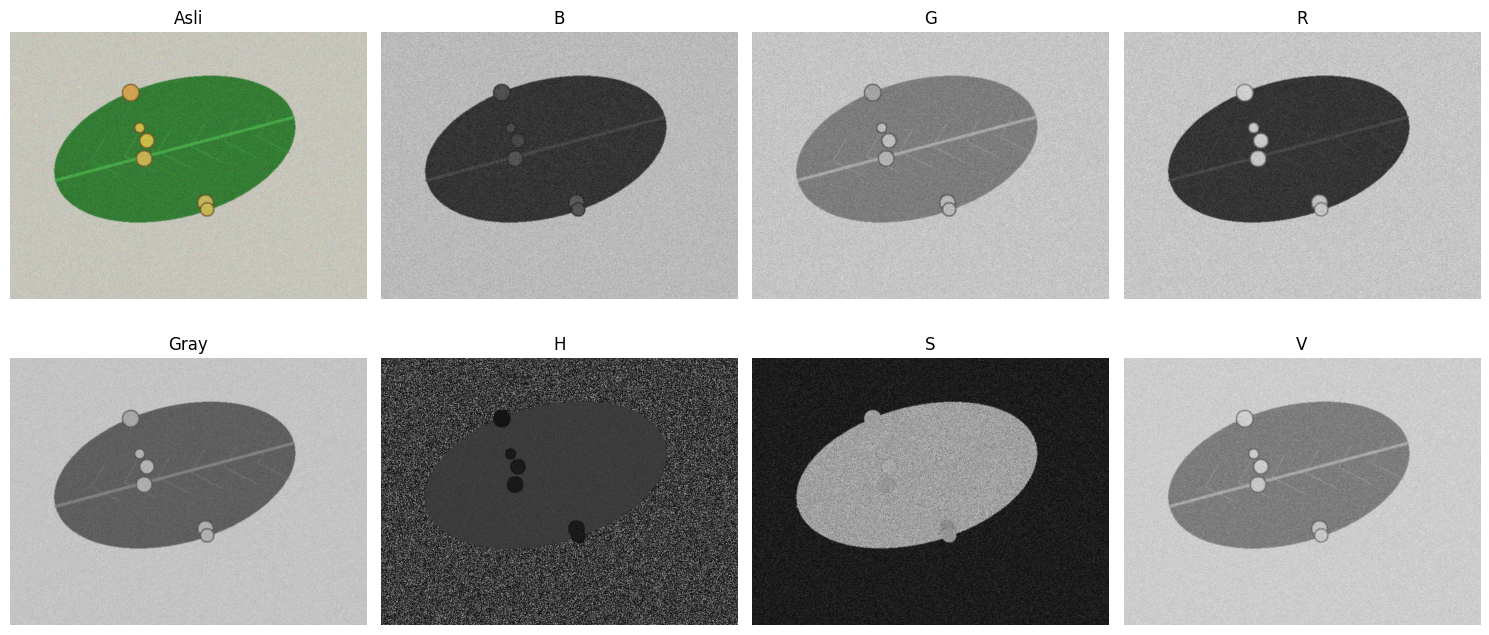

In [5]:
def semua_kanal(img):
    b, g, r = cv2.split(img)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

nama = "teh_041.png"
img = baca(CITRA / nama)
md0 = baca(MASK_DAUN / nama, gray=True)
mb0 = baca(MASK_BERCAK / nama, gray=True)
kanal = semua_kanal(img)
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(15, 7))
kb_satu = pd.DataFrame([[k, kontras_bercak(v, md0, mb0)] for k, v in kanal.items()], columns=["Kanal", "KB"])
display(kb_satu.round(3))
kb_satu.to_csv(HASIL / "b2_kb_teh041.csv", index=False)

## 2.6 Eksperimen sampling dan kuantisasi

Citra diperkecil lalu diperbesar kembali untuk mengamati kehilangan detail. Pada kuantisasi, jumlah bit yang lebih kecil menyisakan level intensitas yang lebih sedikit.

,Faktor,Ukuran kecil,KB setelah diperbesar
0,0.50,320 x 240,7.031
1,0.20,128 x 96,6.092
2,0.10,64 x 48,4.238
3,0.05,32 x 24,2.494


,Bit,Level intensitas terpakai,KB
0,1,2,6.000
1,2,4,6.106
2,3,7,3.210
3,4,12,4.931
4,8,170,5.515


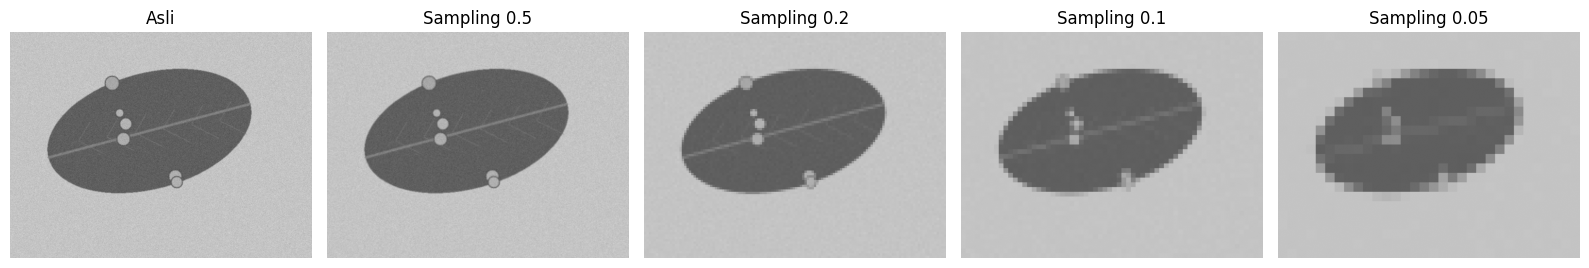

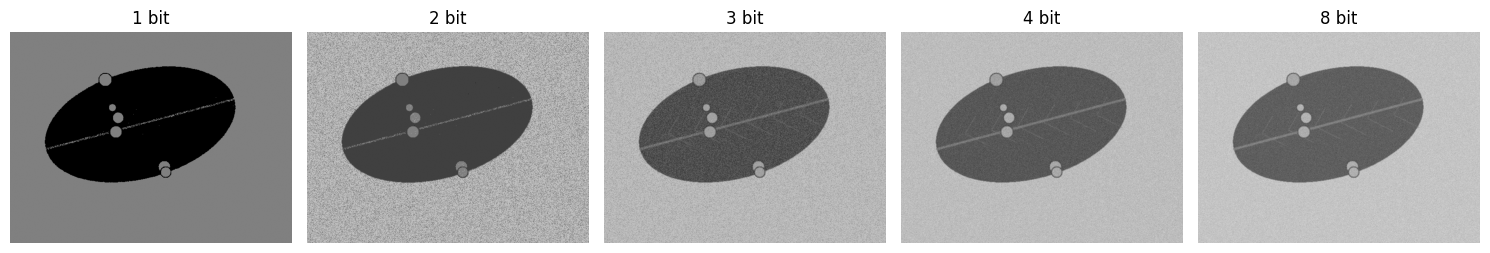

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
baris_sampling, panel_sampling, judul_sampling = [], [gray], ["Asli"]
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    baris_sampling.append([fx, f"{kecil.shape[1]} x {kecil.shape[0]}", kontras_bercak(besar, md0, mb0)])
    panel_sampling.append(besar); judul_sampling.append(f"Sampling {fx}")
tabel_sampling = pd.DataFrame(baris_sampling, columns=["Faktor", "Ukuran kecil", "KB setelah diperbesar"])
display(tabel_sampling.round(3))
tampil(panel_sampling, judul_sampling, baris=1, ukuran=(16, 3))
tabel_sampling.to_csv(HASIL / "b2_sampling.csv", index=False)

baris_kuantisasi, panel_kuantisasi, judul_kuantisasi = [], [], []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    baris_kuantisasi.append([k, int(np.unique(kuant).size), kontras_bercak(kuant, md0, mb0)])
    panel_kuantisasi.append(kuant); judul_kuantisasi.append(f"{k} bit")
tabel_kuantisasi = pd.DataFrame(baris_kuantisasi, columns=["Bit", "Level intensitas terpakai", "KB"])
display(tabel_kuantisasi.round(3))
tampil(panel_kuantisasi, judul_kuantisasi, baris=1, ukuran=(15, 3))
tabel_kuantisasi.to_csv(HASIL / "b2_kuantisasi.csv", index=False)

## 2.7 Rerata KB per kanal untuk kelas berat dan ringan

Hitung seluruh 20 citra kelas berat dan seluruh 20 citra kelas ringan, kemudian rata-ratakan per kondisi cahaya.

In [7]:
def hitung_kb_per_kelas(kelas):
    baris = []
    for _, d in label[label["kelas"] == kelas].iterrows():
        im = baca(CITRA / d.nama_file)
        m_d = baca(MASK_DAUN / d.nama_file, gray=True)
        m_b = baca(MASK_BERCAK / d.nama_file, gray=True)
        nilai = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        nilai["kondisi"] = d.kondisi_cahaya
        baris.append(nilai)
    detail = pd.DataFrame(baris)
    rerata = detail.groupby("kondisi").mean(numeric_only=True).reindex(KONDISI).round(2)
    return detail, rerata

detail_berat, kb_berat = hitung_kb_per_kelas("berat")
detail_ringan, kb_ringan = hitung_kb_per_kelas("ringan")
print("Rerata KB kelas bercak berat:"); display(kb_berat)
print("Rerata KB kelas bercak ringan:"); display(kb_ringan)
kb_berat.to_csv(HASIL / "b2_kb_kanal_berat.csv")
kb_ringan.to_csv(HASIL / "b2_kb_kanal_ringan.csv")
detail_berat.to_csv(HASIL / "b2_kb_detail_berat.csv", index=False)
detail_ringan.to_csv(HASIL / "b2_kb_detail_ringan.csv", index=False)

rerata_gabungan = pd.concat([kb_berat.mean(), kb_ringan.mean()], axis=1)
rerata_gabungan.columns = ["Berat", "Ringan"]
rerata_gabungan["Rata-rata dua kelas"] = rerata_gabungan.mean(axis=1)
rerata_gabungan = rerata_gabungan.sort_values("Rata-rata dua kelas", ascending=False)
KANAL_TERBAIK = str(rerata_gabungan.index[0])
print("Kanal terbaik berdasarkan rerata dua kelas:", KANAL_TERBAIK)
display(rerata_gabungan.round(2))

Rerata KB kelas bercak berat:


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
normal,2.14,1.74,8.81,5.05,5.78,0.83,3.25
gelap,1.05,1.61,9.00,4.52,4.73,0.73,3.09
terang,2.60,0.50,6.11,3.30,4.84,1.58,1.49
kontras_rendah,1.20,1.05,4.79,3.12,2.45,0.09,2.04
bayangan,1.36,0.70,5.19,2.13,3.32,0.73,1.42


Rerata KB kelas bercak ringan:


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
normal,1.26,0.35,8.21,2.99,7.10,0.85,1.51
gelap,1.41,1.00,9.13,3.76,5.82,1.16,2.28
terang,1.19,0.74,6.41,2.92,5.59,0.74,1.30
kontras_rendah,0.67,0.28,2.96,1.41,1.57,0.30,0.84
bayangan,0.34,0.44,4.33,0.87,4.87,0.49,0.35


Kanal terbaik berdasarkan rerata dua kelas: R


,Berat,Ringan,Rata-rata dua kelas
R,6.78,6.21,6.49
H,4.22,4.99,4.61
Gray,3.62,2.39,3.01
V,2.26,1.26,1.76
B,1.67,0.97,1.32
G,1.12,0.56,0.84
S,0.79,0.71,0.75


## 2.8 Tampilkan kanal terbaik pada teh_021 dan teh_045

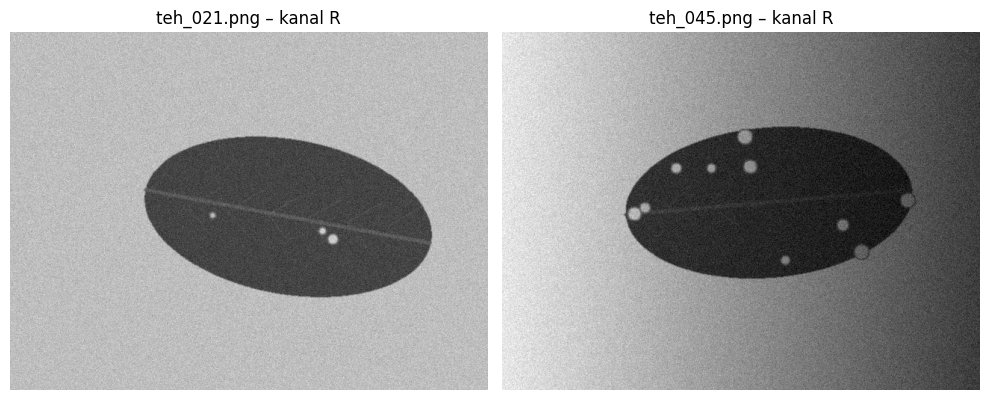

In [8]:
panel, judul = [], []
for nama in ["teh_021.png", "teh_045.png"]:
    im = baca(CITRA / nama)
    ch = semua_kanal(im)[KANAL_TERBAIK]
    panel.append(ch); judul.append(f"{nama} – kanal {KANAL_TERBAIK}")
tampil(panel, judul, baris=1, ukuran=(10, 4))

## 2.9 Pertanyaan analisis P2

Jawab di laporan dengan merujuk tabel/gambar yang dihasilkan: **P2.1** aturan jarak dan resolusi; **P2.2** kanal dengan KB tertinggi dan alasan fisiknya; **P2.3** bandingkan kanal H dan V pada gelap, terang, dan bayangan; **P2.4** keterbatasan KB saat kuantisasi; **P2.5** faktor sampling saat bercak mulai sulit terlihat dan hubungkan dengan hitungan 2.1; **P2.6** risiko kebocoran metadata EXIF.

**Bukti Bagian 2:** lembar hitung, rencana akuisisi, panel kanal, tabel KB kelas berat/ringan, sampling, dan kuantisasi.